# 03_01 The Multivariate Normal

**Learning objectives**
- Describe the **multivariate Normal** by its mean vector $\boldsymbol\mu$ and **covariance matrix** $\Sigma$, and read the ellipses of its density.
- Use its closed-form **marginals**, **conditionals** and **linear transformations**.
- Compute and interpret the **Mahalanobis distance** and its chi-square law, and sample with the **Cholesky factor**.
- Solve an outlier-detection problem and a portfolio problem by hand, in code and by simulation.

**Prerequisites:** [00_03 Joint and conditional distributions](../../module_00_foundations/notebooks/00_03_joint_conditional.ipynb), [02_01 Normal](../../module_02_continuous/notebooks/02_01_uniform_normal.ipynb), [02_08 Chi-square](../../module_02_continuous/notebooks/02_08_t_chisquare_f.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- A random **vector** $\mathbf X=(X_1,\dots,X_d)$ has a mean vector $\boldsymbol\mu$ and a **covariance matrix** $\Sigma$ with $\Sigma_{ij}=\mathrm{Cov}(X_i,X_j)$ (variances on the diagonal).
- $\Sigma$ is **symmetric** and **positive semi-definite**; the **eigenvalues** of $\Sigma$ are variances along the principal axes.
- **Matrix algebra:** $\Sigma^{-1}$ (inverse), $\det\Sigma$ (determinant), $A^\top$ (transpose), Cholesky factor $L$ with $\Sigma=LL^\top$.
- The sum of $d$ squared independent standard normals is $\chi^2_d$ (02_08).

## 3. Intuition and story

One Normal bell describes one variable. When several variables move together (height and weight, two stock returns, pixel intensities), the natural model is a **multivariate Normal**: a bell-shaped hill whose horizontal cross-sections are **ellipses**. The mean vector says where the hill is centered; the covariance matrix says how it is stretched and tilted. Strongly correlated variables give long thin tilted ellipses.

Why is it so important? Everything is closed-form: marginals and conditionals are again Normal, linear combinations are Normal, and zero covariance means independence. Gaussian processes, Kalman filters, PCA, LDA, VAEs and factor models are built on it.

## 4. Formal definition

$\mathbf X\sim N_d(\boldsymbol\mu,\Sigma)$ with $\Sigma$ positive definite has density
$$f(\mathbf x)=\frac{1}{(2\pi)^{d/2}|\Sigma|^{1/2}}\exp\!\Big(-\tfrac12(\mathbf x-\boldsymbol\mu)^\top\Sigma^{-1}(\mathbf x-\boldsymbol\mu)\Big).$$
The quantity $d_M^2=(\mathbf x-\boldsymbol\mu)^\top\Sigma^{-1}(\mathbf x-\boldsymbol\mu)$ is the squared **Mahalanobis distance**: the distance from the center measured in "standard deviations" that respect the correlations. Contours of $f$ are the ellipses $d_M^2=c$. For $d=1$ it reduces to the ordinary Normal.

**`scipy`:** `stats.multivariate_normal(mean, cov)` with `.pdf`, `.logpdf`, `.cdf`, `.rvs`.

## 5. Derivations

**Ellipses and eigenvectors.** Write $\Sigma=Q\Lambda Q^\top$ ($Q$ orthogonal columns = eigenvectors, $\Lambda$ = eigenvalues $\lambda_i$). Then $d_M^2=\sum_i\frac{y_i^2}{\lambda_i}$ with $\mathbf y=Q^\top(\mathbf x-\boldsymbol\mu)$: the contours are ellipses with axes along the eigenvectors and semi-lengths $\sqrt{c\lambda_i}$.

**Mahalanobis distance is chi-square.** Let $\mathbf Z=L^{-1}(\mathbf X-\boldsymbol\mu)$ with $\Sigma=LL^\top$. Then $\mathbf Z\sim N(0,I)$ (standard, independent components) and $d_M^2=\mathbf Z^\top\mathbf Z=\sum Z_i^2\sim\chi^2_d$. Hence $P(d_M^2\le c)=F_{\chi^2_d}(c)$: the ellipse with $c=\chi^2_{d,0.95}$ contains 95 % of the probability. For $d=2$, $P(d_M^2>c)=e^{-c/2}$.

**Linear transformations.** If $\mathbf Y=A\mathbf X+\mathbf b$ then $\mathbf Y\sim N(A\boldsymbol\mu+\mathbf b,\ A\Sigma A^\top)$. Special cases: a weighted sum $\mathbf w^\top\mathbf X\sim N(\mathbf w^\top\boldsymbol\mu,\ \mathbf w^\top\Sigma\mathbf w)$; the marginal of a subset of components is Normal with the matching sub-vector and sub-matrix.

**Conditionals.** Partition $\mathbf X=(\mathbf X_a,\mathbf X_b)$. Then
$$\mathbf X_a\mid\mathbf X_b=\mathbf x_b\ \sim\ N\!\Big(\boldsymbol\mu_a+\Sigma_{ab}\Sigma_{bb}^{-1}(\mathbf x_b-\boldsymbol\mu_b),\ \ \Sigma_{aa}-\Sigma_{ab}\Sigma_{bb}^{-1}\Sigma_{ba}\Big).$$
The conditional mean is linear in $\mathbf x_b$; the conditional covariance (a "Schur complement") does **not** depend on $\mathbf x_b$ and is never larger than $\Sigma_{aa}$.

**Independence.** Jointly Normal components are independent **iff** their covariance is 0 (a property of the Normal only).

**Sampling.** Draw $\mathbf Z\sim N(0,I)$ and set $\mathbf X=\boldsymbol\mu+L\mathbf Z$: then $\mathrm{Cov}(\mathbf X)=LL^\top=\Sigma$.

**In plain words.** The multivariate Normal is a stretched and rotated bell; Mahalanobis distance undoes the stretching, so unusualness is measured on a fair scale.

## 6. Properties and relationships

- **Marginals** of a joint Normal are Normal, but Normal marginals do **not** imply a joint Normal (copulas, 03_04).
- **PCA** diagonalizes $\Sigma$: the principal axes are its eigenvectors.
- **Whitening** $\mathbf Z=L^{-1}(\mathbf X-\boldsymbol\mu)$ gives uncorrelated unit-variance variables.
- **Mahalanobis vs Euclidean:** two points at the same Euclidean distance from the mean can have very different Mahalanobis distances (along vs across the long axis).
- **Max entropy:** the Normal has maximum entropy among distributions with a given mean and covariance.
- **Curse of dimensionality:** in high dimensions most of the mass sits in a thin shell where $d_M^2\approx d$.

## 7. 2D visuals

### 7.1 Ellipses, eigenvectors and the effect of the covariance
Four covariance matrices with the same mean: the eigenvectors (arrows) point along the principal axes and the ellipses contain 50 %, 90 % and 99 % of the probability.

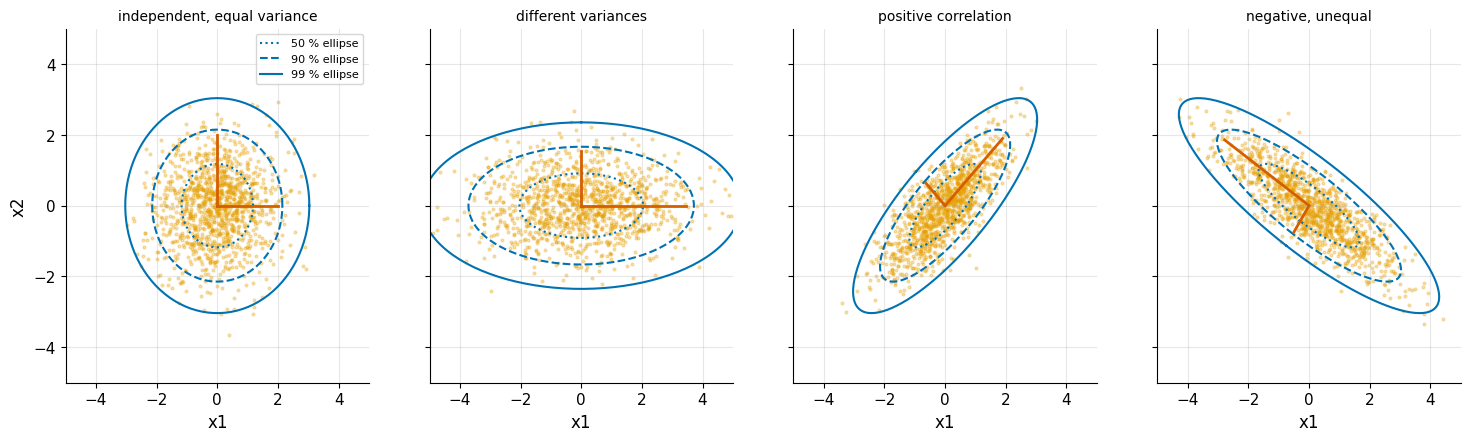

In [2]:
covariances = {"independent, equal variance": [[1, 0], [0, 1]], "different variances": [[3, 0], [0, 0.6]], "positive correlation": [[1, 0.8], [0.8, 1]], "negative, unequal": [[2, -1.2], [-1.2, 1]]}
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6), sharex=True, sharey=True)
theta = np.linspace(0, 2 * np.pi, 200)
for ax, (name, cov) in zip(axes, covariances.items()):
    cov = np.array(cov, dtype=float)
    points = rng.multivariate_normal([0, 0], cov, size=1200)
    ax.scatter(points[:, 0], points[:, 1], s=4, alpha=0.3, color=SIM)
    eigenvalues, eigenvectors = np.linalg.eigh(cov)
    for level, style in [(0.5, ":"), (0.9, "--"), (0.99, "-")]:
        c = stats.chi2(2).ppf(level)
        ellipse = eigenvectors @ (np.sqrt(c * eigenvalues)[:, None] * np.vstack([np.cos(theta), np.sin(theta)]))
        ax.plot(ellipse[0], ellipse[1], style, color=MAIN, label=f"{int(level * 100)} % ellipse")
    for value, vector in zip(eigenvalues, eigenvectors.T):
        ax.plot([0, 2 * np.sqrt(value) * vector[0]], [0, 2 * np.sqrt(value) * vector[1]], color=HIGHLIGHT, linewidth=2)
    ax.set_title(name, fontsize=10)
    ax.set_xlabel("x1")
    ax.set_xlim(-5, 5); ax.set_ylim(-5, 5)
axes[0].set_ylabel("x2")
axes[0].legend(fontsize=8)
plt.show()

### 7.2 Mahalanobis versus Euclidean distance
Points A and B are at the same Euclidean distance from the center, but B lies across the narrow direction and is far more unusual. The colored contours are Mahalanobis distance.

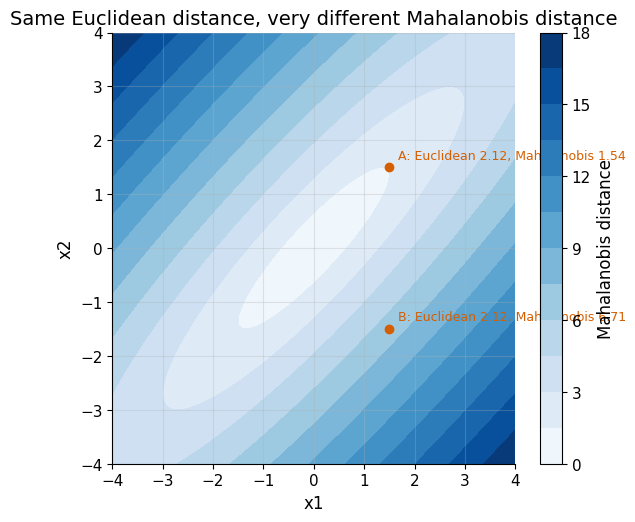

In [3]:
cov = np.array([[1, 0.9], [0.9, 1]])
inverse = np.linalg.inv(cov)
grid = np.linspace(-4, 4, 200)
G1, G2 = np.meshgrid(grid, grid)
stacked = np.dstack([G1, G2])
mahalanobis_sq = np.einsum("...i,ij,...j->...", stacked, inverse, stacked)

point_a, point_b = np.array([1.5, 1.5]), np.array([1.5, -1.5])
fig, ax = plt.subplots(figsize=(6.5, 5.6))
contour = ax.contourf(G1, G2, np.sqrt(mahalanobis_sq), levels=12, cmap="Blues")
plt.colorbar(contour, label="Mahalanobis distance")
for point, name in [(point_a, "A"), (point_b, "B")]:
    d = np.sqrt(point @ inverse @ point)
    ax.plot(*point, "o", color=HIGHLIGHT)
    ax.annotate(f"{name}: Euclidean {np.linalg.norm(point):.2f}, Mahalanobis {d:.2f}", point, textcoords="offset points", xytext=(6, 6), fontsize=9, color=HIGHLIGHT)
ax.set_title("Same Euclidean distance, very different Mahalanobis distance")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
plt.show()

### 7.3 Marginals and conditionals of a bivariate Normal
For correlation 0.8, conditioning on x1 = 1.5 shifts and narrows the distribution of x2 (the dashed curves); the marginal is the wide curve.

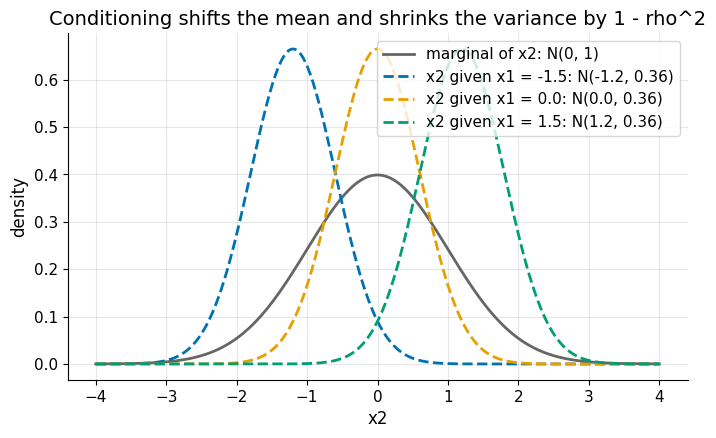

In [4]:
rho = 0.8
y_axis = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(y_axis, stats.norm(0, 1).pdf(y_axis), color=NEUTRAL, linewidth=2, label="marginal of x2: N(0, 1)")
for x1, color in zip([-1.5, 0.0, 1.5], COLORS):
    ax.plot(y_axis, stats.norm(rho * x1, np.sqrt(1 - rho**2)).pdf(y_axis), "--", color=color, linewidth=2, label=f"x2 given x1 = {x1}: N({rho * x1:.1f}, {1 - rho**2:.2f})")
ax.set_title("Conditioning shifts the mean and shrinks the variance by 1 - rho^2")
ax.set_xlabel("x2")
ax.set_ylabel("density")
ax.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: the density surface and its elliptical contours

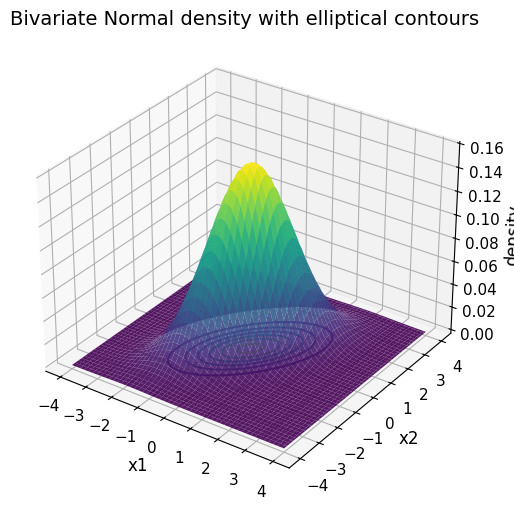

In [5]:
cov = np.array([[1.0, 0.7], [0.7, 1.5]])
dist2 = stats.multivariate_normal([0, 0], cov)
grid = np.linspace(-4, 4, 100)
G1, G2 = np.meshgrid(grid, grid)
density = dist2.pdf(np.dstack([G1, G2]))
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(G1, G2, density, cmap="viridis", edgecolor="none", alpha=0.9)
ax.contour(G1, G2, density, zdir="z", offset=0, levels=6, cmap="viridis")
ax.set_title("Bivariate Normal density with elliptical contours")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("density")
ax.view_init(elev=30, azim=-55)
plt.show()

### 8.2 Static: a trivariate Normal cloud
Samples from a 3D Normal form an ellipsoid; colour is the Mahalanobis distance.

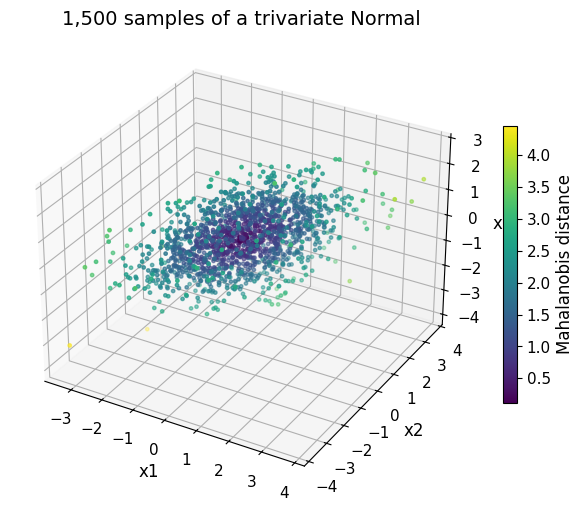

In [6]:
cov3 = np.array([[1.0, 0.8, 0.3], [0.8, 1.0, 0.2], [0.3, 0.2, 1.0]])
cloud = rng.multivariate_normal([0, 0, 0], cov3, size=1500)
distances = np.sqrt(np.einsum("ni,ij,nj->n", cloud, np.linalg.inv(cov3), cloud))
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
scatter = ax.scatter(cloud[:, 0], cloud[:, 1], cloud[:, 2], c=distances, cmap="viridis", s=6)
plt.colorbar(scatter, label="Mahalanobis distance", shrink=0.6)
ax.set_title("1,500 samples of a trivariate Normal")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("x3")
plt.show()

### 8.3 Interactive Plotly version of the density surface

In [7]:
fig = go.Figure(go.Surface(x=grid, y=grid, z=density, colorscale="Viridis"))
fig.update_layout(title="Bivariate Normal density", width=750, height=550, scene=dict(xaxis_title="x1", yaxis_title="x2", zaxis_title="density"))
fig.show()

## 9. Simulation vs theory

### 9.1 Sampling with the Cholesky factor, and the chi-square law of d^2

sample mean: [ 0.997 -2.001]  (theory [ 1. -2.] )
sample covariance:
 [[3.985 1.794]
 [1.794 0.999]] 
 theory:
 [[4.  1.8]
 [1.8 1. ]]


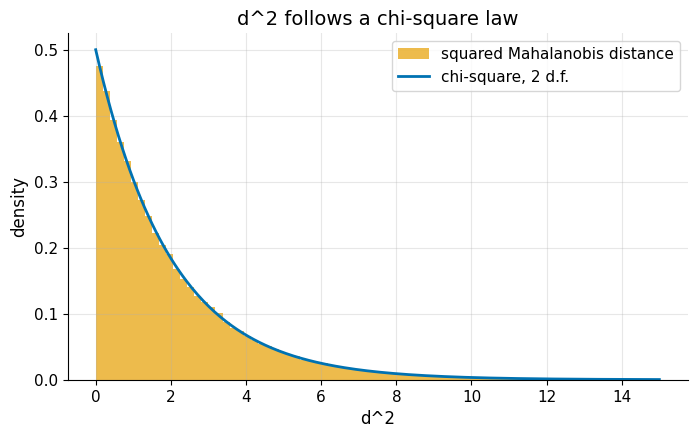

KS p-value: 0.928


In [8]:
mu = np.array([1.0, -2.0])
sigma = np.array([[4.0, 1.8], [1.8, 1.0]])
L = np.linalg.cholesky(sigma)
z = rng.normal(size=(200_000, 2))
x = mu + z @ L.T                                    # X = mu + L Z
print("sample mean:", x.mean(axis=0).round(3), " (theory", mu, ")")
print("sample covariance:\n", np.cov(x.T).round(3), "\n theory:\n", sigma)

d2 = np.einsum("ni,ij,nj->n", x - mu, np.linalg.inv(sigma), x - mu)
fig, ax = plt.subplots()
ax.hist(d2, bins=80, range=(0, 15), density=True, color=SIM, alpha=0.7, label="squared Mahalanobis distance")
grid_d = np.linspace(0, 15, 300)
ax.plot(grid_d, stats.chi2(2).pdf(grid_d), color=MAIN, linewidth=2, label="chi-square, 2 d.f.")
ax.set_title("d^2 follows a chi-square law")
ax.set_xlabel("d^2")
ax.set_ylabel("density")
ax.legend()
plt.show()
print("KS p-value:", round(stats.kstest(d2, stats.chi2(2).cdf).pvalue, 3))

### 9.2 Coverage of the ellipses

ellipse d^2 <= 1.386: expected 0.50, simulated 0.5003
ellipse d^2 <= 4.605: expected 0.90, simulated 0.8995
ellipse d^2 <= 9.210: expected 0.99, simulated 0.9900


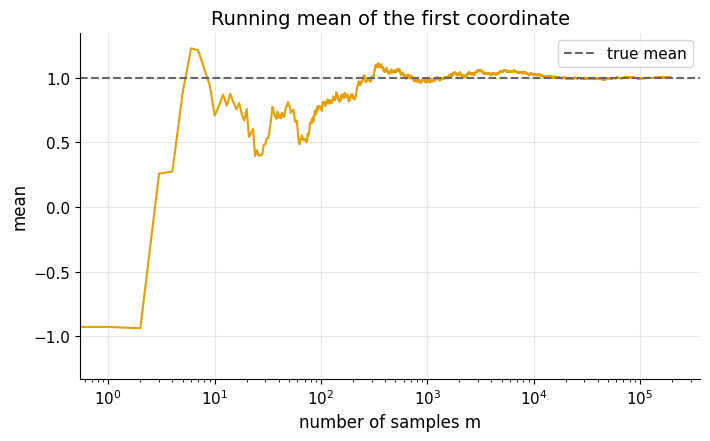

In [9]:
for level in (0.5, 0.9, 0.99):
    c = stats.chi2(2).ppf(level)
    print(f"ellipse d^2 <= {c:.3f}: expected {level:.2f}, simulated {np.mean(d2 <= c):.4f}")
running_mean = np.cumsum(x[:, 0]) / np.arange(1, len(x) + 1)
fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM)
ax.axhline(mu[0], color=NEUTRAL, linestyle="--", label="true mean")
ax.set_xscale("log")
ax.set_title("Running mean of the first coordinate")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

In [10]:
from scipy.spatial import distance
mvn = stats.multivariate_normal(mean=mu, cov=sigma)
print("pdf at the mean   :", round(mvn.pdf(mu), 5), " (= 1 / (2 pi sqrt(det))) =", round(1 / (2 * np.pi * np.sqrt(np.linalg.det(sigma))), 5))
print("logpdf at (3, 0)  :", round(mvn.logpdf([3, 0]), 4))
print("cdf(2, -1)        :", round(mvn.cdf([2, -1]), 4))
print("rvs(2)            :", mvn.rvs(size=2, random_state=1).round(2).tolist())
print("Mahalanobis (3, 0):", round(distance.mahalanobis([3, 0], mu, np.linalg.inv(sigma)), 4))
print("eigenvalues       :", np.linalg.eigvalsh(sigma).round(4), " trace =", np.trace(sigma))

pdf at the mean   : 0.18256  (= 1 / (2 pi sqrt(det))) = 0.18256
logpdf at (3, 0)  : -5.3849
cdf(2, -1)        : 0.6825
rvs(2)            : [[-2.13, -3.74], [2.23, -1.89]]
Mahalanobis (3, 0): 2.7145
eigenvalues       : [0.1569 4.8431]  trace = 5.0


## 11. Real-world worked example: spotting an unusual person (height and weight)

**Scenario (illustrative numbers).** Height $H$ (cm) and weight $W$ (kg) are bivariate Normal with $\boldsymbol\mu=(170,70)$ and $\Sigma=\begin{pmatrix}64&57.6\\57.6&144\end{pmatrix}$ (SDs 8 and 12, correlation 0.6). A record shows a person who is **185 cm and 55 kg**.

**Questions**
1. What is the **Mahalanobis distance** of this person? Are the height and weight each unusual on their own?
2. What fraction of people are **at least this unusual** (the p-value)?
3. What are the **semi-axis lengths** of the 95 % ellipse?

### 11.1 By hand
Difference from the mean: $\mathbf d=(15,-15)$. $\det\Sigma=64\cdot144-57.6^2=9216-3317.76=5898.24$ and $\Sigma^{-1}=\frac1{5898.24}\begin{pmatrix}144&-57.6\\-57.6&64\end{pmatrix}$.

**Q1.** $d_M^2=\frac{144\cdot15^2-2\cdot57.6\cdot15\cdot(-15)+64\cdot15^2}{5898.24}=\frac{32400+25920+14400}{5898.24}=\frac{72720}{5898.24}=12.33$, so $d_M=3.51$. Separately: height $z=\frac{15}8=1.88$ and weight $z=\frac{-15}{12}=-1.25$ are unremarkable, but tall **and** light together contradicts the positive correlation.

**Q2.** For $d=2$, $P(\chi^2_2>c)=e^{-c/2}=e^{-6.165}=0.0021$: about 1 person in 480.

**Q3.** Eigenvalues of $\Sigma$: $\lambda=\frac{208\pm\sqrt{(144-64)^2+4\cdot57.6^2}}2=\frac{208\pm\sqrt{6400+13271.04}}2=\frac{208\pm140.25}2$: $\lambda_1=174.1$, $\lambda_2=33.9$. With $c=\chi^2_{2,0.95}=5.991$: semi-axes $\sqrt{5.991\lambda}$: $32.3$ and $14.3$.

In [11]:
import math

mu_hw = np.array([170.0, 70.0])
cov_hw = np.array([[64.0, 57.6], [57.6, 144.0]])
person = np.array([185.0, 55.0])
d = person - mu_hw

det = cov_hw[0, 0] * cov_hw[1, 1] - cov_hw[0, 1] ** 2
d_squared_hand = (cov_hw[1, 1] * d[0] ** 2 - 2 * cov_hw[0, 1] * d[0] * d[1] + cov_hw[0, 0] * d[1] ** 2) / det
p_value_hand = math.exp(-d_squared_hand / 2)
discriminant = math.sqrt((cov_hw[0, 0] - cov_hw[1, 1]) ** 2 + 4 * cov_hw[0, 1] ** 2)
eigenvalues_hand = [(cov_hw[0, 0] + cov_hw[1, 1] + sign * discriminant) / 2 for sign in (+1, -1)]
chi_95 = -2 * math.log(0.05)                                   # chi-square(2) 95 % quantile = -2 ln(0.05)
semi_axes_hand = [math.sqrt(chi_95 * lam) for lam in eigenvalues_hand]
print(f"d^2 = {d_squared_hand:.3f}, d = {math.sqrt(d_squared_hand):.3f}, p-value = {p_value_hand:.5f}; eigenvalues {np.round(eigenvalues_hand, 2)}; semi-axes {np.round(semi_axes_hand, 2)}")
print(f"separate z-scores: height {d[0] / 8:.3f}, weight {d[1] / 12:.3f}")

d^2 = 12.329, d = 3.511, p-value = 0.00210; eigenvalues [174.13  33.87]; semi-axes [32.3  14.25]
separate z-scores: height 1.875, weight -1.250


### 11.2 In code with `scipy`, and the asserts

In [12]:
d_squared_code = d @ np.linalg.inv(cov_hw) @ d
p_value_code = stats.chi2(2).sf(d_squared_code)
eigenvalues_code, eigenvectors_code = np.linalg.eigh(cov_hw)
semi_axes_code = np.sqrt(stats.chi2(2).ppf(0.95) * eigenvalues_code[::-1])

assert np.isclose(d_squared_hand, d_squared_code)
assert np.isclose(p_value_hand, p_value_code)
assert np.allclose(sorted(eigenvalues_hand), eigenvalues_code)
assert np.allclose(semi_axes_hand, semi_axes_code)
print(f"d^2 = {d_squared_code:.3f}; p-value = {p_value_code:.5f}; semi-axes {semi_axes_code.round(2)}; main axis direction {eigenvectors_code[:, 1].round(3)}")

d^2 = 12.329; p-value = 0.00210; semi-axes [32.3  14.25]; main axis direction [0.463 0.886]


### 11.3 Verify by simulation

In [13]:
people = rng.multivariate_normal(mu_hw, cov_hw, size=2_000_000)
d2_people = np.einsum("ni,ij,nj->n", people - mu_hw, np.linalg.inv(cov_hw), people - mu_hw)
print(f"share with d^2 >= {d_squared_code:.2f}: exact {p_value_code:.5f}, simulated {np.mean(d2_people >= d_squared_code):.5f}")
inside = np.mean(d2_people <= stats.chi2(2).ppf(0.95))
print(f"share inside the 95 % ellipse: {inside:.4f}")
print(f"share beyond +-1.88 SD in height alone: {2 * stats.norm.sf(1.875):.4f}; people at least as unusual in both: {np.mean(d2_people >= d_squared_code):.5f}")
assert abs(np.mean(d2_people >= d_squared_code) - p_value_code) < 0.0005
assert abs(inside - 0.95) < 0.002

share with d^2 >= 12.33: exact 0.00210, simulated 0.00213
share inside the 95 % ellipse: 0.9499
share beyond +-1.88 SD in height alone: 0.0608; people at least as unusual in both: 0.00213


### 11.4 Plots

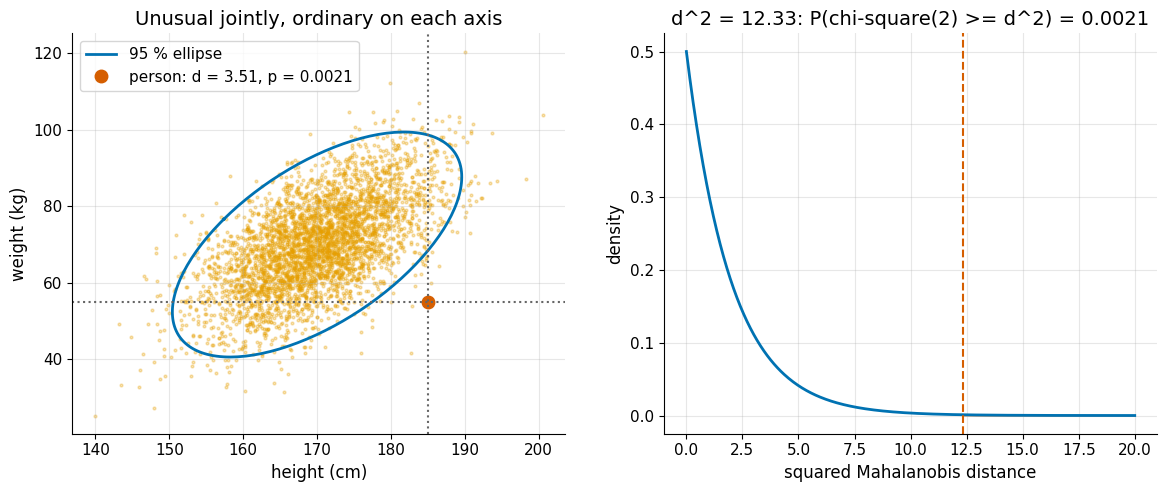

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sample = people[:4000]
axes[0].scatter(sample[:, 0], sample[:, 1], s=4, alpha=0.3, color=SIM)
c95 = stats.chi2(2).ppf(0.95)
vals, vecs = np.linalg.eigh(cov_hw)
theta = np.linspace(0, 2 * np.pi, 200)
ellipse = mu_hw[:, None] + vecs @ (np.sqrt(c95 * vals)[:, None] * np.vstack([np.cos(theta), np.sin(theta)]))
axes[0].plot(ellipse[0], ellipse[1], color=MAIN, linewidth=2, label="95 % ellipse")
axes[0].plot(*person, "o", color=HIGHLIGHT, markersize=9, label=f"person: d = {np.sqrt(d_squared_code):.2f}, p = {p_value_code:.4f}")
axes[0].axvline(185, color=NEUTRAL, linestyle=":")
axes[0].axhline(55, color=NEUTRAL, linestyle=":")
axes[0].set_title("Unusual jointly, ordinary on each axis")
axes[0].set_xlabel("height (cm)")
axes[0].set_ylabel("weight (kg)")
axes[0].legend()

grid_d = np.linspace(0, 20, 400)
axes[1].plot(grid_d, stats.chi2(2).pdf(grid_d), color=MAIN, linewidth=2)
tail = grid_d >= d_squared_code
axes[1].fill_between(grid_d[tail], stats.chi2(2).pdf(grid_d[tail]), color=HIGHLIGHT, alpha=0.5)
axes[1].axvline(d_squared_code, color=HIGHLIGHT, linestyle="--")
axes[1].set_title(f"d^2 = {d_squared_code:.2f}: P(chi-square(2) >= d^2) = {p_value_code:.4f}")
axes[1].set_xlabel("squared Mahalanobis distance")
axes[1].set_ylabel("density")
plt.show()

### 11.5 Interpretation and decision
- A person of **185 cm and 55 kg** has height z-score 1.9 and weight z-score -1.25: neither is alarming alone. But together the Mahalanobis distance is **3.5** (d squared 12.3): only **0.2 % of people** (about 1 in 480) are this unusual.
- **Decision:** a data-quality check using each variable's z-score separately would miss this record; a check using the Mahalanobis distance (threshold $d^2>9.21$ for the 99 % ellipse) catches it. Flag the record for review (a typo, a sensor error or a rare person).

### 11.6 Extra example: a two-asset portfolio
Two assets have yearly returns with means 8 % and 5 %, SDs 20 % and 10 %, and correlation 0.3. A portfolio holds **60 % in asset 1 and 40 % in asset 2**. The portfolio return is the weighted sum $\mathbf w^\top\mathbf R$.

In [15]:
w = np.array([0.6, 0.4])
mean_returns = np.array([0.08, 0.05])
sds = np.array([0.20, 0.10])
corr = 0.3
cov_assets = np.array([[sds[0] ** 2, corr * sds[0] * sds[1]], [corr * sds[0] * sds[1], sds[1] ** 2]])

mean_hand = 0.6 * 0.08 + 0.4 * 0.05
variance_hand = 0.6**2 * 0.20**2 + 0.4**2 * 0.10**2 + 2 * 0.6 * 0.4 * corr * 0.20 * 0.10
mean_code, variance_code = w @ mean_returns, w @ cov_assets @ w
assert np.isclose(mean_hand, mean_code) and np.isclose(variance_hand, variance_code)
returns = rng.multivariate_normal(mean_returns, cov_assets, size=500_000) @ w
print(f"portfolio mean {mean_code:.4f}, SD {np.sqrt(variance_code):.4f} (simulated {returns.mean():.4f}, {returns.std():.4f}); weighted average of the SDs would be {w @ sds:.3f}")
print(f"P(loss) = {stats.norm(mean_code, np.sqrt(variance_code)).cdf(0):.4f}, simulated {np.mean(returns < 0):.4f}")
assert abs(returns.std() - np.sqrt(variance_code)) < 0.001

portfolio mean 0.0680, SD 0.1374 (simulated 0.0678, 0.1373); weighted average of the SDs would be 0.160
P(loss) = 0.3103, simulated 0.3106


**Interpretation.** The portfolio has mean return **6.8 %** and SD **13.7 %**, less than the weighted average of the two SDs (16 %): **diversification** works because the correlation is below 1. The variance of a sum needs the full covariance matrix: $\mathbf w^\top\Sigma\mathbf w$.

## 12. Where it is used

### Statistics
- **Multivariate analysis:** MANOVA, Hotelling's $T^2$, discriminant analysis (LDA), factor analysis, Gaussian likelihoods and the sampling distribution of means in several dimensions.

### Data science
- **Outlier and anomaly detection** by Mahalanobis distance, PCA and whitening, portfolio and risk models, uncertainty ellipses for 2D estimates.

### ML and AI
- **Gaussian processes** (any finite set of function values is multivariate Normal), **Kalman filters**, **VAEs** (Gaussian latents), Gaussian mixture models (03_03), Naive/Linear discriminant classifiers, covariance-aware losses.

## 13. Common pitfalls and misconceptions

- **Euclidean distance ignores correlation;** use Mahalanobis distance for unusualness.
- **Normal marginals do not imply a joint Normal:** the dependence can have a different shape (copulas).
- **Covariance matrices must be positive semi-definite;** a hand-built matrix with large off-diagonals may not be valid (check eigenvalues).
- **Estimated covariance in high dimensions is unstable** (needs n much larger than d; use shrinkage).
- **d squared ~ chi-square needs the true mean and covariance;** with estimates the distribution is slightly different (Hotelling's T squared / F).
- **Zero correlation implies independence only for jointly Normal variables.**

## 14. Exercises

1. For $\Sigma=\begin{pmatrix}4&2\\2&3\end{pmatrix}$, find the correlation and the eigenvalues.
2. $\mathbf X\sim N((0,0),I_2)$. What is the probability that $\|\mathbf X\|^2\le5.99$? What is it for $d=3$ with the same threshold?
3. For the height-weight model, find the distribution of the **BMI-like combination** $W-0.5H$ (mean and SD).
4. Using the conditional formula, find the distribution of $W$ given $H=160$ for the height-weight model.
5. (Harder) Show by simulation that if $\mathbf X\sim N(\boldsymbol\mu,\Sigma)$ then $A\mathbf X$ has covariance $A\Sigma A^\top$, for a random $2\times2$ matrix $A$.

Solutions are at the end.

## 15. Summary table

| Item | Formula | `scipy` / `numpy` |
|---|---|---|
| Density | exp(-d^2 / 2) / ((2 pi)^(d/2) sqrt(det Sigma)) | `multivariate_normal.pdf` |
| Mahalanobis d^2 | (x - mu)^T Sigma^-1 (x - mu) ~ chi-square(d) | `distance.mahalanobis` |
| Linear map | A X + b ~ N(A mu + b, A Sigma A^T) | matrix products |
| Conditional | N(mu_a + S_ab S_bb^-1 (x_b - mu_b), S_aa - S_ab S_bb^-1 S_ba) | formula |
| Sampling | mu + L z, Sigma = L L^T | `np.linalg.cholesky`, `rvs` |
| Ellipse axes | eigenvectors, semi-lengths sqrt(c lambda) | `np.linalg.eigh` |

## Solutions

In [16]:
s1 = np.array([[4.0, 2.0], [2.0, 3.0]])
print("1: correlation =", round(2 / np.sqrt(12), 4), " eigenvalues =", np.linalg.eigvalsh(s1).round(4))
print("2: P(chi2(2) <= 5.99) =", round(stats.chi2(2).cdf(5.99), 4), " d = 3:", round(stats.chi2(3).cdf(5.99), 4))
a = np.array([-0.5, 1.0])
print("3: W - 0.5 H mean =", a @ mu_hw, " SD =", round(float(np.sqrt(a @ cov_hw @ a)), 4))
print("4: W | H = 160: mean =", 70 + 57.6 / 64 * (160 - 170), " SD =", round(float(np.sqrt(144 - 57.6**2 / 64)), 4))
A = rng.normal(size=(2, 2))
transformed = (rng.multivariate_normal([0, 0], cov_hw, size=500_000)) @ A.T
print("5: simulated cov of A X:\n", np.cov(transformed.T).round(1), "\n A Sigma A^T:\n", (A @ cov_hw @ A.T).round(1))

1: correlation = 0.5774  eigenvalues = [1.4384 5.5616]
2: P(chi2(2) <= 5.99) = 0.95  d = 3: 0.8879
3: W - 0.5 H mean = -15.0  SD = 10.1193
4: W | H = 160: mean = 61.0  SD = 9.6
5: simulated cov of A X:
 [[962.7 319.3]
 [319.3 126.4]] 
 A Sigma A^T:
 [[964.1 319.8]
 [319.8 126.6]]


**1.** $\rho=2/\sqrt{4\cdot3}=0.577$; eigenvalues $\frac{7\pm\sqrt{1+16}}2=5.56$ and $1.44$.

**2.** $P(\chi^2_2\le5.99)=0.95$; for $d=3$ the same threshold covers only $0.888$ (more dimensions, more spread).

**3.** Mean $=70-0.5\cdot170=-15$; variance $=\mathbf a^\top\Sigma\mathbf a=0.25\cdot64+144-2\cdot0.5\cdot57.6=16+144-57.6=102.4$, SD $10.12$.

**4.** Mean $=70+0.9\times(-10)=61$; variance $=144-57.6^2/64=144-51.84=92.16$, SD $9.6$.

**5.** The simulated covariance matches $A\Sigma A^\top$ (printed).